# 05 Steals and busts

**Question:** which players did far better or far worse than their draft slot predicted, and which franchises have historically drafted above or below expectations?

Method:
1. Work out the **expected** `ws_first4` for every pick: what a typical player at that slot produces.
2. **Surplus** = actual `ws_first4` − expected.
3. The biggest positive surplus = **steals**; the biggest negative = **busts**.
4. Average the surplus by franchise to compare teams.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression

In [3]:
players = pd.read_csv("../data/processed/draft_players_targets.csv")

players["log_pick"] = np.log(players["overall_pick"])

## Expected value of each pick

I fit a linear regression of `ws_first4` on `log_pick`, using **all 1,742 picks**:

**expected `ws_first4` = 22.89 − 5.41 × log(pick)**

| Pick | 1 | 5 | 14 | 30 | 45 | 60 |
|---|---|---|---|---|---|---|
| Expected | 22.9 | 14.2 | 8.6 | 4.5 | 2.3 | 0.7 |

Why this formula:
- **The shape:** notebook 03 (Q1) showed value drops fast for early picks and slowly for late ones. A straight line
  on log(pick) becomes that curve when drawn against the pick number.
- **Why log:** notebook 04 showed log(pick) fits better than the raw pick number (MAE 4.55 vs 4.73).
- **Why not the median per pick:** each pick has only about 30 players, so the medians are noisy. One smooth formula
  gives a fairer benchmark.
- **Why all the data here:** notebook 04 predicted the future, so it tested on unseen drafts. This notebook describes
  the past, so I use every draft to set the benchmark.
- **Why only log_pick:** I want to compare each player with their draft slot only, not their background.

In [4]:
X = players[["log_pick"]]
y = players["ws_first4"]

model = LinearRegression()
model.fit(X, y)

print(model.intercept_)
print(model.coef_)

22.890196677500757
[-5.41457127]


Every player at the same pick gets the same expected value, because the formula's only input is the pick.
The expected value describes a typical player at that slot, not the individual player.

In [5]:
players["expected"] = model.predict(X)
players[["player", "overall_pick", "ws_first4", "expected"]].head()

,player,overall_pick,ws_first4,expected
0,Pervis Ellison,1,15.2,22.890197
1,Danny Ferry,2,5.9,19.137102
2,Sean Elliott,3,27.9,16.941682
3,Glen Rice,4,20.0,15.384007
4,J.R. Reid,5,8.4,14.175780


## Surplus and the biggest steals

**Surplus = actual − expected.** Positive means the player did better than a typical player at that pick.

**Top steals:** Chris Paul (pick 4, +39.9), Shawn Marion (pick 9), LeBron James (pick 1), Paul Pierce (pick 10), Dirk Nowitzki (pick 9).
Even a number 1 pick can be a steal if they far exceed what a typical number 1 pick produces.

In [6]:
players["surplus"] = players["ws_first4"] - players["expected"]

cols = ["player", "draft_year", "overall_pick", "draft_team", "ws_first4", "expected", "surplus"]

steals = players.nlargest(10, "surplus")[cols].round(1)
steals

,player,draft_year,overall_pick,draft_team,ws_first4,expected,surplus
905,Chris Paul,2005,4,NOH,55.3,15.4,39.9
563,Shawn Marion,1999,9,PHO,38.6,11.0,27.6
785,LeBron James,2003,1,CLE,49.4,22.9,26.5
506,Paul Pierce,1998,10,BOS,36.4,10.4,26.0
505,Dirk Nowitzki,1998,9,MIL,36.9,11.0,25.9
1408,Rudy Gobert,2013,27,DEN,30.4,5.0,25.4
162,Shaquille O'Neal,1992,1,ORL,48.2,22.9,25.3
272,Grant Hill,1994,3,DET,41.9,16.9,25.0
440,Tim Duncan,1997,1,SAS,47.7,22.9,24.8
789,Dwyane Wade,2003,5,MIA,38.8,14.2,24.6


## The biggest busts

**Top busts:** Michael Olowokandi, Anthony Bennett and Markelle Fultz (all number 1 picks), Adam Morrison (pick 3), Jay Williams (pick 2).

- **Busts only come from the top of the draft.** Win shares can't go far below 0, so the worst possible surplus is
  about 0 − expected. A pick-1 player can miss by about 23; a pick-50 player can only miss by about 1.5.
- **"Bust" doesn't always mean bad scouting.** Jay Williams had a motorcycle accident and Greg Oden had serious knee
  injuries. The data shows what happened, not why.

In [7]:
busts = players.nsmallest(10, "surplus")[cols].round(1)
busts

,player,draft_year,overall_pick,draft_team,ws_first4,expected,surplus
497,Michael Olowokandi,1998,1,LAC,0.1,22.9,-22.8
1382,Anthony Bennett,2013,1,CLE,0.5,22.9,-22.4
1622,Markelle Fultz,2017,1,PHI,3.1,22.9,-19.8
964,Adam Morrison,2006,3,CHA,-1.5,16.9,-18.4
729,Jay Williams,2002,2,CHI,0.8,19.1,-18.3
1625,Josh Jackson,2017,4,PHO,-1.8,15.4,-17.2
1022,Greg Oden,2007,1,POR,6.8,22.9,-16.1
732,Nikoloz Tskitishvili,2002,5,DEN,-1.6,14.2,-15.8
786,Darko Miličić,2003,2,DET,4.1,19.1,-15.0
1565,Dragan Bender,2016,4,PHO,0.6,15.4,-14.8


## Second round gems (picks 31–60)

The best second round picks: **Nikola Jokić** (pick 41, +24.3), Paul Millsap (pick 47), **Isaiah Thomas** (pick 60, the last pick
of 2011), Mitchell Robinson (pick 36), Draymond Green (pick 35), Marc Gasol (pick 48).

Nobody expected much from these picks (2–4 win shares), so their success is the biggest surprise in the data.

In [8]:
second_round = players[players["overall_pick"] > 30]

gems = second_round.nlargest(10, "surplus")[cols].round(1)
gems

,player,draft_year,overall_pick,draft_team,ws_first4,expected,surplus
1482,Nikola Jokić,2014,41,DEN,27.1,2.8,24.3
1008,Paul Millsap,2006,47,UTA,24.8,2.0,22.8
1321,Isaiah Thomas,2011,60,SAC,23.1,0.7,22.4
1717,Mitchell Robinson,2018,36,NYK,24.8,3.5,21.3
1356,Draymond Green,2012,35,GSW,24.7,3.6,21.1
1069,Marc Gasol,2007,48,LAL,22.7,1.9,20.8
1299,Chandler Parsons,2011,38,HOU,23.5,3.2,20.3
655,Michael Redd,2000,43,MIL,22.2,2.5,19.7
252,Nick Van Exel,1993,37,LAL,22.7,3.3,19.4
761,Carlos Boozer,2002,35,CLE,22.9,3.6,19.3


## Steals and busts on one chart

Each dot is one player; the black line is the expected value for each pick.
**Green** names are the biggest steals and **red** names are the biggest busts.

Steals sit far above the line across the draft, while the busts are all at the top picks, near 0 win shares.

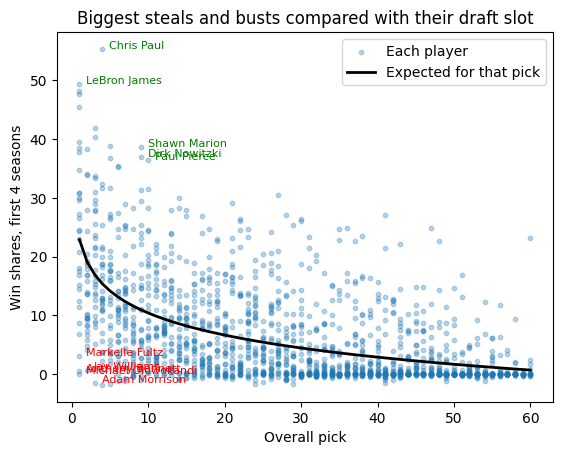

In [9]:
curve = players.sort_values("overall_pick")

plt.scatter(players["overall_pick"], players["ws_first4"], s=10, alpha=0.3, label="Each player")
plt.plot(curve["overall_pick"], curve["expected"], linewidth=2, color="black", label="Expected for that pick")

for player, row in steals.head(5).iterrows():
    plt.annotate(row["player"], (row["overall_pick"], row["ws_first4"]), xytext=(5, 0), textcoords="offset points", fontsize=8, color="green")

for player, row in busts.head(5).iterrows():
    plt.annotate(row["player"], (row["overall_pick"], row["ws_first4"]), xytext=(5, 0), textcoords="offset points", fontsize=8, color="red")

plt.xlabel("Overall pick")
plt.ylabel("Win shares, first 4 seasons")
plt.title("Biggest steals and busts compared with their draft slot")
plt.legend()
plt.show()

## Which franchises drafted best?

Some franchises moved or were renamed between 1989 and 2018, so I merge old codes into the current franchise
(for example SEA : OKC, NJN : BRK, VAN : MEM). The original Charlotte Hornets (CHH) count for Charlotte (CHO),
because the NBA returned that history to Charlotte in 2014.

For each franchise I calculate the number of picks and the **average surplus per pick**.
Surplus already adjusts for draft position, so teams with high and low picks can be compared fairly.

In [ ]:
teams_map = {"NJN": "BRK",
         "SEA": "OKC",
         "VAN": "MEM",
         "WSB": "WAS",
         "NOH": "NOP",
         "NOK": "NOP",
         "CHA": "CHO",
         "CHH": "CHO"}

players["franchise"] = players["draft_team"].replace(teams_map)

team_stats = players.groupby("franchise").agg(picks=("player", "size"), avg_surplus=("surplus", "mean"),)

df = pd.DataFrame(team_stats)
print(df.sort_values(by="avg_surplus", ascending=False))

           picks  avg_surplus
franchise                    
DET           58     1.884395
HOU           58     1.681812
GSW           58     1.446004
LAL           54     1.297030
SAS           55     0.950736
IND           51     0.879655
NOP           26     0.871920
DEN           62     0.863986
OKC           72     0.769114
MIL           65     0.703504
UTA           67     0.520879
CLE           51     0.407227
TOR           37     0.330274
BRK           52     0.231389
PHO           71     0.033646
MIA           49    -0.061148
CHI           70    -0.083149
CHO           51    -0.359357
MIN           72    -0.382629
ATL           73    -0.428786
BOS           66    -0.601229
NYK           45    -0.614789
MEM           45    -0.618787
SAC           64    -0.735960
PHI           77    -0.754955
ORL           62    -0.839125
DAL           59    -1.200793
WAS           55    -1.223408
POR           63    -1.296284
LAC           54    -2.950094


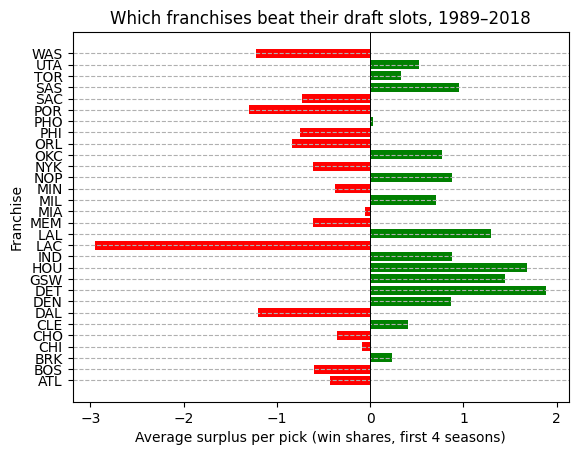

In [36]:
colors=[]
for v in team_stats["avg_surplus"]:
    if v > 0:
        colors.append("green")
    else:
        colors.append("red")

plt.barh(team_stats.index, team_stats["avg_surplus"], color=colors)
plt.axvline(0, color="black", linewidth=0.7)
plt.xlabel("Average surplus per pick (win shares, first 4 seasons)")
plt.ylabel("Franchise")
plt.title("Which franchises beat their draft slots, 1989–2018")
plt.grid(axis="y", linestyle="--", alpha=1)
plt.show()

**Findings**
- Most franchises are within about ±1.5 win shares per pick of expectations.
- Detroit (+1.88), Houston (+1.68) and Golden State (+1.45) drafted best; the Clippers (−2.95) are clearly last.
- New Orleans has only 26 picks (its history starts in 2002), so its average is less reliable.

**Cautions**
- `draft_team` is the team that **made** the pick, not where the player played. Dirk Nowitzki counts for Milwaukee
  and Marc Gasol for the Lakers, though both were traded right away.
- One star can lift a team's whole average, and 30 years cover many different front offices.
  This ranking is suggestive, not proof of any team's current drafting skill.

## Answer and summary

**Question:** which players did far better or far worse than their draft slot predicted, and which franchises have historically drafted above or below expectations?

**Answer**
- **Players who beat their draft slot the most:** Chris Paul (pick 4, +39.9 win shares above expected), Shawn Marion,
  LeBron James, Paul Pierce and Dirk Nowitzki. The best second-round picks were Nikola Jokić (pick 41),
  Paul Millsap (47) and Isaiah Thomas (60, the last pick of 2011).
- **Players who missed their draft slot the most:** Michael Olowokandi, Anthony Bennett and Markelle Fultz
  (all number 1 picks), Adam Morrison and Jay Williams.
- **Teams:** from 1989 to 2018, Detroit (+1.88 per pick), Houston (+1.68) and Golden State (+1.45) drafted most above
  expectations, and the Clippers (−2.95) furthest below. This describes how each franchise's picks turned out over
  30 years; it does not prove any team's current front office is better at drafting.

**Summary**
- A pick's expected value falls from about 23 win shares (pick 1) to under 1 (pick 60).
- Steals come from anywhere in the draft, including the second round.
- Big busts only come from the top picks, because only high picks carry high expectations to miss.
- Most teams draft close to expectations; the differences between teams are small and noisy.